# Results

In [35]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


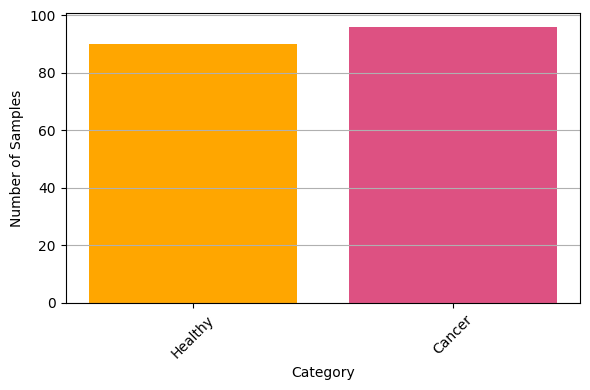


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [2]:
class_task = "healthy_vs_cancer"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [3]:
m = SVC(kernel="rbf", C=1.0, probability=True)

# select freq and IIVV and shape data
X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [4]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)

y_true = np.array(y_true)
y_score = np.array(y_score)

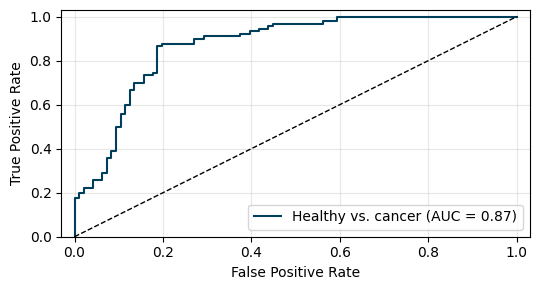

In [5]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_SVM_baseline.pdf",
)

**RF**

In [6]:
m = RandomForestClassifier(
    n_estimators=100,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=4,
)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [7]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

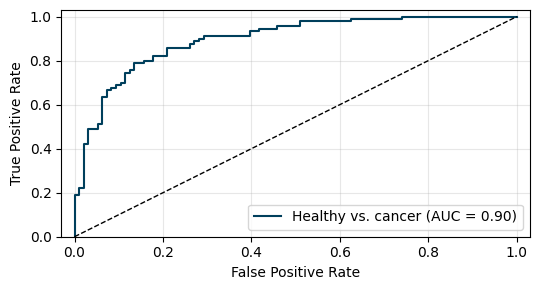

In [8]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_RF_baseline.pdf",
)

**LR**

In [9]:
m = LogisticRegression(C=0.01, max_iter=100)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(186, 239568)


In [10]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

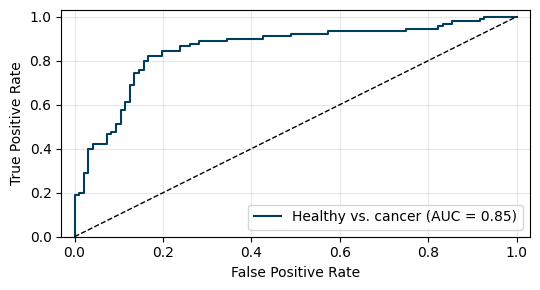

In [11]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_LR_baseline.pdf",
)

## Task 2 : Cancer versus HBD


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. HDB

Non-cancer: 162 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Non-cancer']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Non-cancer'): [0, 1]}


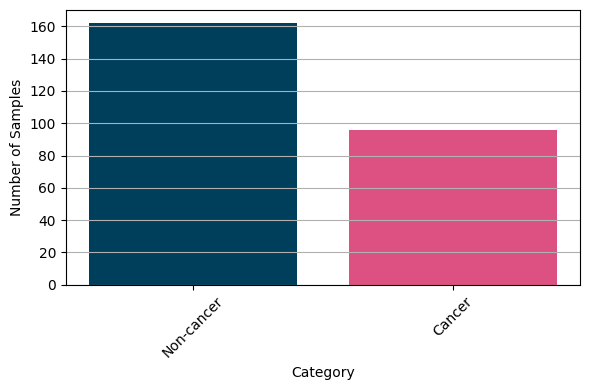


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Non-cancer'}
(258, 31, 7728) (258, 2) (258,)


In [12]:
class_task = "cancer_vs_hbd"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [13]:
m = SVC(kernel="linear", C=0.001, probability=True, random_state=0)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(258, 239568)


In [14]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

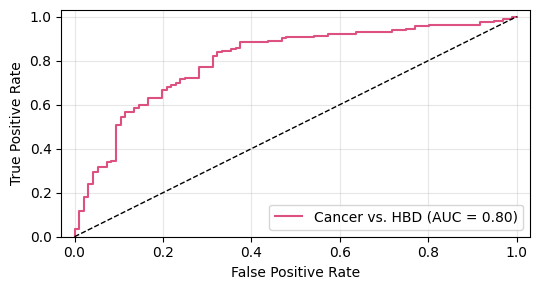

In [15]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_SVM_baseline.pdf",
)

**RF**

In [16]:
m = RandomForestClassifier(
    n_estimators=800,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=4,
)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(258, 239568)


In [17]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

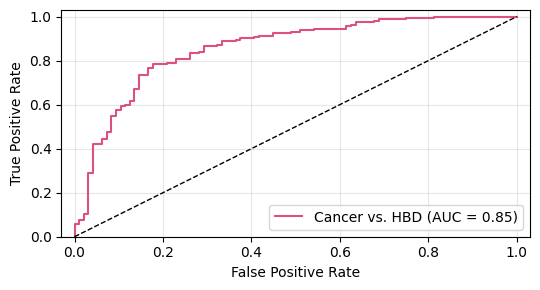

In [18]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_RF_baseline.pdf",
)

**LR**

In [19]:
m = LogisticRegression(C=0.01, max_iter=100)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(258, 239568)


In [20]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

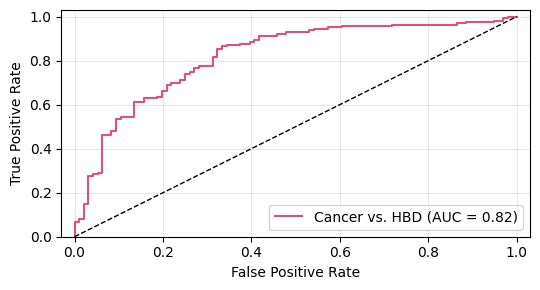

In [21]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_LR_baseline.pdf",
)

## Task 3: Multiclass

In [43]:
class_task = "MC"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
Severe dysplasia: 29 entries
Benign: 41 entries
Available cases: ['Benign' 'Cancer' 'Healthy' 'Severe dysplasia']
Coding: -> forward
{np.str_('Benign'): [1, 0, 0, 0], np.str_('Cancer'): [0, 1, 0, 0], np.str_('Healthy'): [0, 0, 1, 0], np.str_('Severe dysplasia'): [0, 0, 0, 1]}

Inverse mapping: {(1, 0, 0, 0): 'Benign', (0, 1, 0, 0): 'Cancer', (0, 0, 1, 0): 'Healthy', (0, 0, 0, 1): 'Severe dysplasia'}
(256, 31, 7728) (256, 4) (256,)


**SVM**

In [44]:
m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(256, 239568)


In [45]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

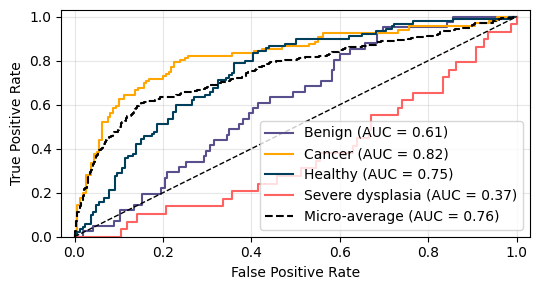

In [46]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_SVM_baseline.pdf",
)

**RF**

In [47]:
m = RandomForestClassifier(
    n_estimators=800,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=1,
)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(256, 239568)


In [48]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

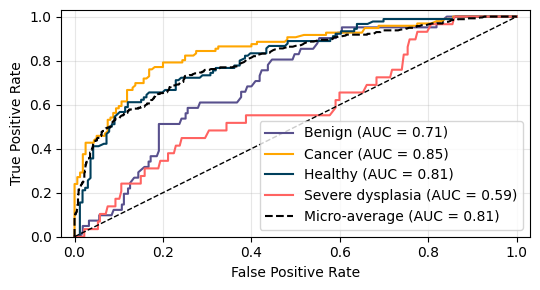

In [49]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_RF_baseline.pdf",
)

**LR**

In [50]:
m = LogisticRegression(C=1.0, max_iter=100)

X_tmp = X[:, :, :]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

(256, 239568)


In [51]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

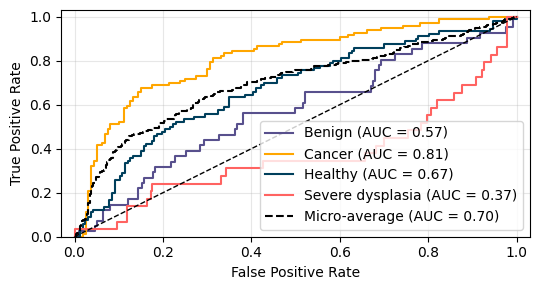

In [52]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_LR_baseline.pdf",
)

## Data augmentation

In [53]:
aug_dict = {
    "Severe dysplasia": 80,
    "Benign": 80,
}

**SVM with data augmentation**

In [54]:
m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

In [55]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        prints=False,
    )
    X_train = X_train[:, :, :]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, :, :]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 82 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 81 entries
Benign: 82 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 84 entries
Benign: 82 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 81 entries


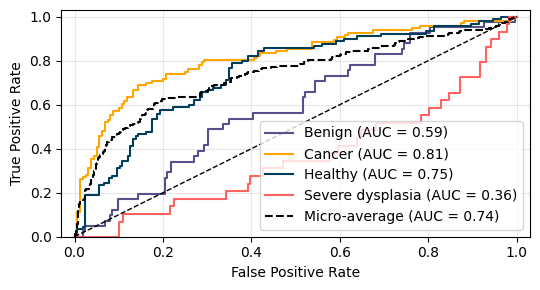

In [56]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_SVM_aug_baseline.pdf",
)

**RF with data augmentation**

In [57]:
m = RandomForestClassifier(
    n_estimators=800,
    max_depth=510,
    max_features="log2",
    min_samples_split=2,
    min_samples_leaf=1,
)

In [58]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        prints=False,
    )
    X_train = X_train[:, :, :]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, :, :]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 82 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 82 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 83 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 82 entries


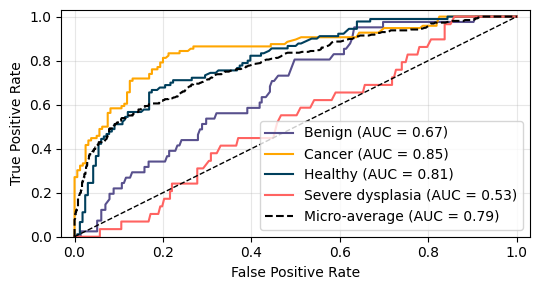

In [59]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_RF_aug_baseline.pdf",
)

**LR with data augmentation**

In [60]:
m = LogisticRegression(C=1.0, max_iter=100)

In [61]:
cv = GroupKFold(n_splits=5)

y_true = []
y_score = []

for train_idx, test_idx in cv.split(X, Y_labels, Case):
    # data augmentation after train/test split
    X_train, y_train, _, _ = augment_patient_and_cat_specific(
        X[train_idx],
        Y_labels[train_idx],
        labels[train_idx],
        Case[train_idx],
        aug_dict,
        prints=False,
    )
    X_train = X_train[:, :, :]
    X_train = X_train.reshape(X_train.shape[0], -1)

    X_test = X[test_idx]
    X_test = X_test[:, :, :]
    X_test = X_test.reshape(X_test.shape[0], -1)
    y_test = Y_labels[test_idx]

    m.fit(X_train, y_train)
    probs = m.predict_proba(X_test)
    y_true.extend(y_test)
    y_score.extend(probs)
y_true = np.array(y_true)
y_score = np.array(y_score)

Benign: 81 entries
Cancer: 70 entries
Healthy: 72 entries
Severe dysplasia: 82 entries
Benign: 82 entries
Cancer: 79 entries
Healthy: 71 entries
Severe dysplasia: 81 entries
Benign: 83 entries
Cancer: 78 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 81 entries
Cancer: 79 entries
Healthy: 72 entries
Severe dysplasia: 81 entries
Benign: 81 entries
Cancer: 78 entries
Healthy: 73 entries
Severe dysplasia: 83 entries


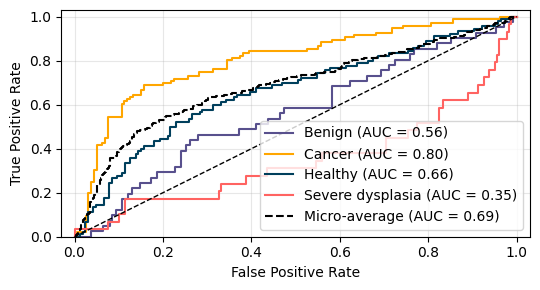

In [63]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"results/ROC_{class_task}_LR_aug_baseline.pdf",
)

___